In [1]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import nuflux
import os
import pandas as pd
import scipy

In [2]:
import toise
from toise import effective_areas
(e_nu, cos_theta, e_mu), efficiency = effective_areas.get_muon_production_efficiency()

In [3]:
help(effective_areas.get_muon_production_efficiency)

Help on function get_muon_production_efficiency in module toise.effective_areas:

get_muon_production_efficiency(ct_edges=None)
    Get the probability that a muon neutrino of energy E_nu from zenith angle
    cos_theta will produce a muon that reaches the detector with energy E_mu

    :param ct_edges: edges of *cos_theta* bins. Efficiencies will be interpolated
        at the centers of these bins. If an integer, interpret as the NSide of
        a HEALpix map
    :returns: a tuple edges, efficiency. *edges* is a 3-element tuple giving the
        edges in E_nu, cos_theta, and E_mu, while *efficiency* is a 3D array
        with the same axes.



In [67]:
# eff = efficiency.mean(axis=0)[:,5,:]
eff = efficiency.mean(axis=0).transpose()[:,6,:]
print('cos_theta: ', cos_theta[6])
cos_theta

cos_theta:  0.20000000000000018


array([-1. , -0.8, -0.6, -0.4, -0.2,  0. ,  0.2,  0.4,  0.6,  0.8,  1. ])

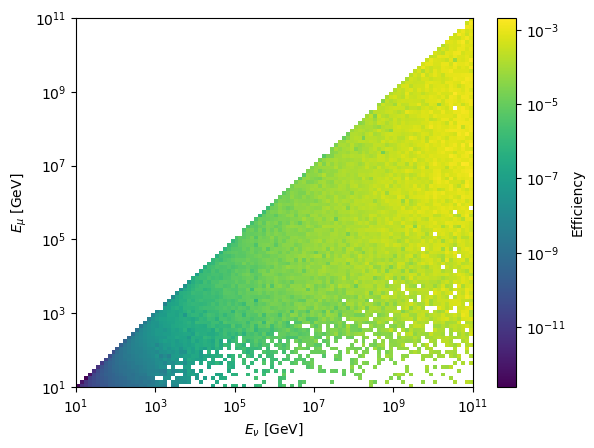

In [69]:
eff = efficiency.mean(axis=0).transpose()[:,5,:]
plt.pcolormesh(e_nu, e_mu, eff, norm=LogNorm())
plt.loglog()
plt.xlabel(r'$E_\nu$ [GeV]')
plt.ylabel(r'$E_\mu$ [GeV]')
plt.colorbar(label='Efficiency')


[]

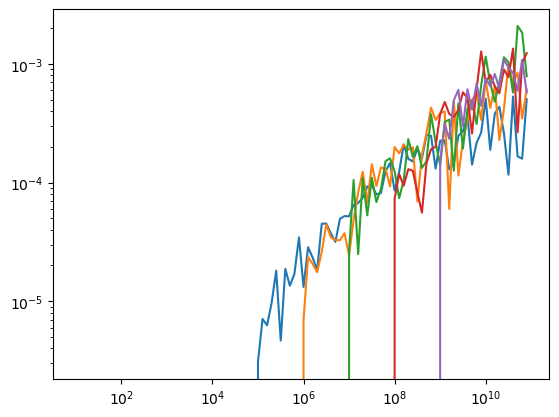

In [19]:
for xi in 40, 50, 60, 70, 80:
    plt.plot(e_nu[:-1], eff[xi,:])
plt.loglog()

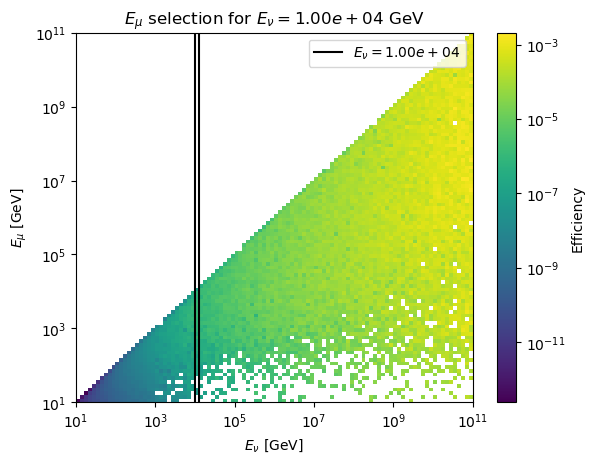

Text(0.5, 0, '$E_\\nu\\;[\\text{GeV}]$')

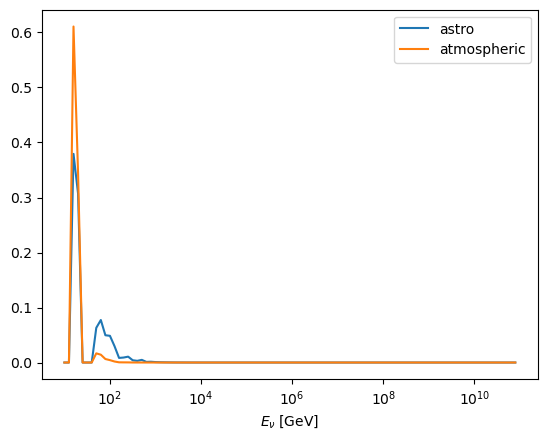

In [21]:
eff = efficiency.mean(axis=0).transpose()[:,5,:]
xi = 30
def norm(x):
    return x/x.sum()


plt.pcolormesh(e_nu, e_mu, eff, norm=LogNorm())
plt.loglog()
plt.xlabel(r'$E_\nu$ [GeV]')
plt.ylabel(r'$E_\mu$ [GeV]')
plt.colorbar(label='Efficiency')
plt.axvline(e_nu[xi], c='black', label=fr'$E_\nu={e_nu[xi]:.2e}$')
plt.axvline(e_nu[xi + 1], c='black')
plt.legend()
plt.title(fr'$E_\mu$ selection for $E_\nu={e_nu[xi]:.2e}$ GeV')
plt.show()


plt.plot(e_nu[:-1], norm(eff[:,xi]*(e_nu[:-1]**-2.13)), label='astro')
plt.plot(e_nu[:-1], norm(eff[:,xi]*(e_nu[:-1]**-3.7)), label='atmospheric')

plt.legend()
plt.semilogx()
# plt.xlim(1e4, 1e5)
plt.xlabel(r'$E_\nu\;[\text{GeV}]$')

# plt.ylim(1e-3, 1)

In [8]:
e_mu[50]

1000000.0

Text(0, 0.5, 'Probability to produce a muon')

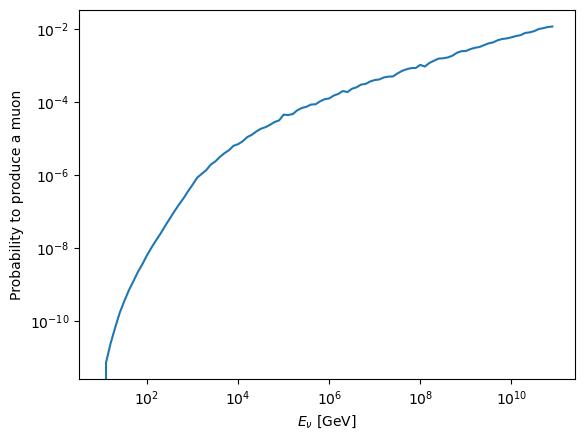

In [9]:
plt.plot(e_nu[:-1], eff.sum(axis=1))
plt.loglog()
plt.xlabel(r'$E_\nu$ [GeV]')
plt.ylabel('Probability to produce a muon')

## Computing Signalness
From the IceCat alerts we have a public **neutrino energy**. We will first use the efficiency matrix to obtain the most likley muon energy. Then, from this muon energy we will compute the most likley neutrino energy assuming a astrophysical / background spectrum. 
Finally, we will compute the signalness. 

In [77]:
def norm(x):
        return x/x.sum()
    
def get_E_nu(E_nu, dec, eff_matrix=eff, gamma_astro=-2.19, gamma_bkg=-3.7, plot_stages=True, e_nu=e_nu, cos_theta=cos_theta,
            e_mu=e_mu, efficiency=efficiency):
    '''
    E_nu: float, GeV
    dec: float, in degrees
    '''

    #first we find the closest cos_theta bin
    closest_cost_theta = list(cos_theta[:-1][cos_theta[:-1] <= np.cos(np.deg2rad(dec))])[-1]
    index_cos_theta = list(cos_theta).index(closest_cost_theta)
    
    eff=efficiency.mean(axis=0).transpose()[:,index_cos_theta,:]
    
    #first get index for closest energy
    closest_E_nu = list(e_nu[e_nu <= E_nu])[-1]
    index_E_nu = list(e_nu).index(closest_E_nu)

    if plot_stages:
        # print('closest cos(theta) = ', closest_cost_theta)
        #plot value we are taking in the matrix
        plt.pcolormesh(e_nu, e_mu, eff, norm=LogNorm())
        plt.loglog()
        plt.xlabel(r'$E_\nu$ [GeV]')
        plt.ylabel(r'$E_\mu$ [GeV]')
        plt.colorbar(label='Efficiency')
        plt.axvline(e_nu[index_E_nu], c='black', label=fr'$E_\nu={e_nu[index_E_nu]:.2e}$')
        plt.axvline(e_nu[index_E_nu + 1], c='black')
        plt.legend()
        plt.title(fr'$E_\mu$ selection for $E_\nu={E_nu:.2e}$ GeV')
        plt.show()

    #Now we plot the respective E_mu distribution to find the maximum:
    #get maximum
    
    weighted_E_mu_dist = norm(eff[:,index_E_nu] )#* e_mu[:-1] ** gamma_astro)
    index_E_mu = list(weighted_E_mu_dist).index(np.max(weighted_E_mu_dist))
    max_E_mu = e_mu[:-1][index_E_mu]

    #Now let's fowrard fold to recover the neutrino and muon energies
    
    # astro_dist = norm(eff[:,index_E_mu]*(e_nu[:-1] **  gamma_astro))
    # bkg_dist =  norm(eff[:,index_E_mu]*(e_nu[:-1] ** gamma_bkg)) 
    
    astro_dist = norm(eff[index_E_mu,:]* (e_nu[:-1] **  gamma_astro))
    bkg_dist =  norm(eff[index_E_mu,:]* (e_nu[:-1] ** gamma_bkg))

    E_nu_astro = e_nu[list(astro_dist).index(np.max(astro_dist))]
    E_nu_bkg = e_nu[list(bkg_dist).index(np.max(bkg_dist))]



    
    if plot_stages:
        plt.plot(e_mu[:-1], weighted_E_mu_dist)
        plt.loglog()
        plt.xlabel(r'$E_\mu$', fontsize=16)
        plt.ylabel(r'Normalized efficiency', fontsize=16)
        plt.title(rf'$E_\mu$ distribution for $E_\nu={e_nu[index_E_nu]:.2e}$ GeV', fontsize=14)
        plt.axvline(max_E_mu, c='black', linestyle='dashed', label=rf'Most likely $E_\mu={max_E_mu:.2e}$ GeV')
        plt.legend()
        plt.show()

        #show the selection in the efficiency table:
        plt.pcolormesh(e_nu, e_mu, eff, norm=LogNorm())
        plt.loglog()
        plt.xlabel(r'$E_\nu$ [GeV]')
        plt.ylabel(r'$E_\mu$ [GeV]')
        plt.colorbar(label='Efficiency')
        plt.axhline(e_mu[index_E_mu], c='black', label=fr'$E_\nu={e_mu[index_E_mu]:.2e}$')
        plt.axhline(e_mu[index_E_mu + 1], c='black')
        plt.legend()
        plt.title(fr'$E_\nu$ selection for $E_\mu={max_E_mu:.2e}$ GeV')
        plt.show()
        
        plt.plot(e_nu[:-1], astro_dist, label='astro', c='blue')
        plt.plot(e_nu[:-1], bkg_dist, label='atmospheric', c='orange')
        plt.xlabel(r'$E_\nu$', fontsize=16)
        plt.ylabel('Normalized efficiency')
        plt.title(rf'$E_\nu$ distribution for $E_\mu = {e_mu[index_E_mu]:.2e}$ GeV')
        plt.axvline(E_nu_astro,  c='blue', linestyle='dashed', label=r'$E_\nu^{astro} =$' + f'{E_nu_astro:.2e} GeV')
        plt.axvline(E_nu_bkg,  c='orange', linestyle='dashed', label=r'$E_\nu^{bkg} =$' + f'{E_nu_bkg:.2e} GeV')
        plt.axvline(E_nu, c='black', linestyle='dashed', label=rf'Initial $E_\nu={E_nu:.2e} $GeV')
        plt.xlim(1e4, 1e6)
        plt.semilogx()
        plt.legend()
        plt.show()

    return E_nu_astro, E_nu_bkg #in GeV

    
    
    

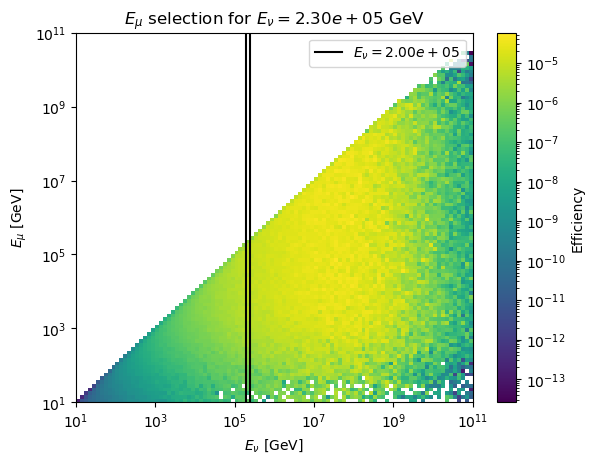

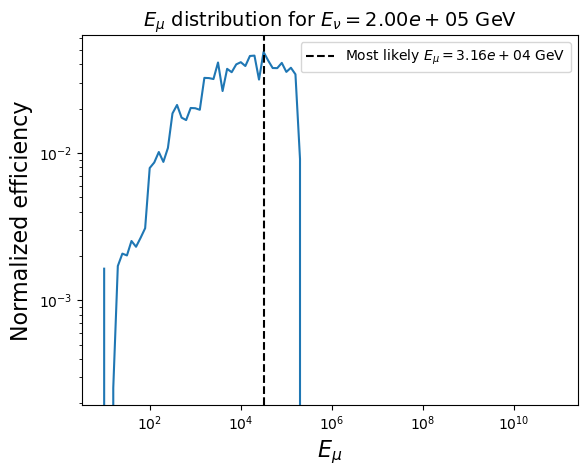

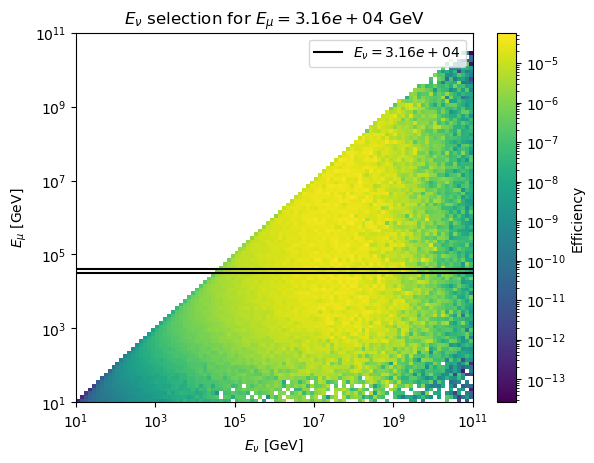

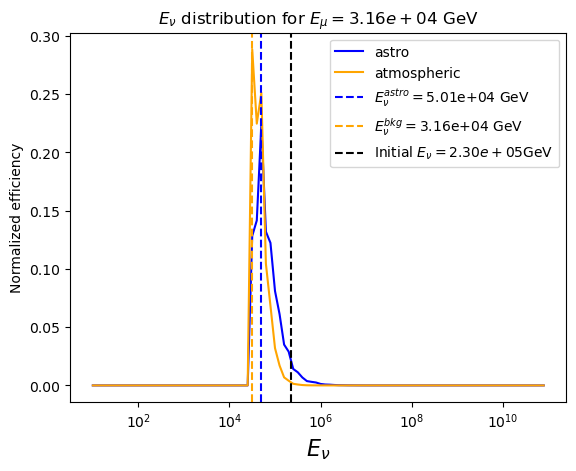

In [39]:
E_nu_astro, E_nu_bkg = get_E_nu(2.3e5, 100, plot_stages=True)

### Signalness computation

In [40]:
def d_N_astro_dE(E_nu, norm=1.01, gamma=2.19):
    '''
    E_nu: float or array, in  GeV
    '''
    return norm * (E_nu * 1e-3  / 100) ** (-1 *gamma) * 1e-18

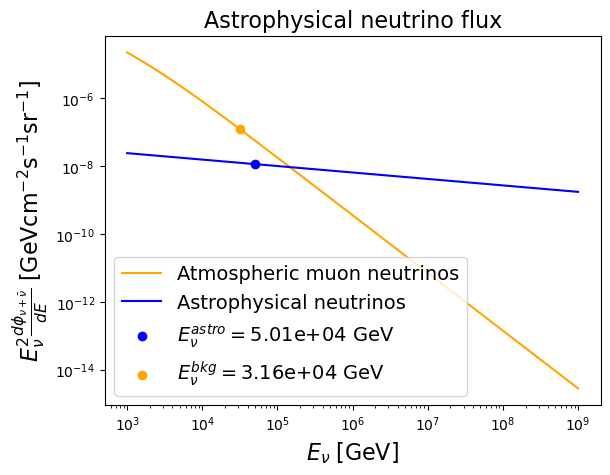

In [43]:
flux = nuflux.makeFlux('honda2006')#('CORSIKA_GaisserH3a_average')
nu_type=nuflux.NuMu
nu_cos_zenith = 0.5

E_range = np.logspace(3, 9, 1000)
plt.plot(E_range, flux.getFlux(nu_type, E_range, nu_cos_zenith) * E_range **  2, label='Atmospheric muon neutrinos', c='orange')
plt.plot(E_range, d_N_astro_dE(E_range) *  E_range **  2, label='Astrophysical neutrinos', c='blue')

# Integration points we just found
plt.scatter(E_nu_astro, d_N_astro_dE(E_nu_astro) *  E_nu_astro **  2, c='blue', label=r'$E_\nu^{astro}=$'+f'{E_nu_astro:.2e} GeV')
plt.scatter(E_nu_bkg, flux.getFlux(nu_type, E_nu_bkg, nu_cos_zenith) * E_nu_bkg **  2, c='orange', label=r'$E_\nu^{bkg}=$'+f'{E_nu_bkg:.2e} GeV')


plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$E_\nu\;[\text{GeV}]$', fontsize=16)
plt.ylabel(r'$E_\nu^2\frac{d\phi_{\nu+\bar \nu}}{dE} \;[\text{GeV}\text{cm}^{-2}\text{s}^{-1}\text{sr}^{-1}]$', fontsize=16)
plt.title("Astrophysical neutrino flux", fontsize=16)
plt.legend(fontsize=14)
plt.show()

In [35]:
def get_signalness_diff(E_nu, dec, nu_type=nuflux.NuMu):

    '''
    E_nu: float or array, in GeV
    dec: float or array,  degree
    '''
    E_nu_astro, E_nu_bkg = get_E_nu(E_nu, dec, plot_stages=False)

    dNs = d_N_astro_dE(E_nu_astro)
    dNb = flux.getFlux(nu_type, E_nu_bkg, np.cos(np.deg2rad(dec)))

    return dNs / (dNs + dNb)

def get_signalness_int(E_nu, dec, channel='', nu_type=nuflux.NuMu, E_max=1e9):

    '''
    E_nu: float or array, in GeV
    dec: float or array,  degree
    '''
    
    E_nu_astro, E_nu_bkg = get_E_nu(E_nu, dec, plot_stages=False)

    E_range_astro = np.logspace(np.log10(E_nu_astro),
                                np.log10(E_max),
                                10000)
    E_range_bkg = np.logspace(np.log10(E_nu_bkg),
                              np.log10(E_max),
                              10000)
    
    A_eff_astro = np.array([effective_area(E, dec, channel=channel)  for E in E_range_astro])
    A_eff_bkg = np.array([effective_area(E, dec, channel=channel)  for E in E_range_bkg])
    
    y_astro = d_N_astro_dE(E_range_astro) * A_eff_astro
    N_s = scipy.integrate.trapezoid(y_astro, E_range_astro)

    y_bkg = flux.getFlux(nu_type, E_range_bkg, np.cos(np.deg2rad(dec))) * A_eff_bkg
    N_b =  scipy.integrate.trapezoid(y_bkg, E_range_bkg)

    return N_s / (N_b + N_s)

    
    

    

    

In [36]:
get_signalness_int(115.0* 1e3, 44.7, channel='gfu-bronze')


0.7094505754392351

### Signalness check from IceCat-1

In [31]:
icecat1_path = '/Users/cristozilleruelo/Desktop/DESY/Thesis/IceCat-1/'
alerts_path = os.path.join(icecat1_path,  'IceCube_Gold_Bronze_Tracks.csv')
eff_areas_path = os.path.join(icecat1_path, 'eff_area', 'Effa_all_streams_gold_bronze.txt')
with open(alerts_path, 'r') as file:
    ic_alerts = pd.read_csv(file)

#get effective areas:
with open(eff_areas_path,  'r') as file:
    eff_areas = pd.read_table(file)
ic_alerts[['DEC', 'DEC_ERR_MINUS', 'DEC_ERR_PLUS', 'ENERGY', 'SIGNAL', 'FAR']]
ic_alerts['I3TYPE']

0        gfu-gold
1        gfu-gold
2      gfu-bronze
3       hese-gold
4      gfu-bronze
          ...    
343    gfu-bronze
344    gfu-bronze
345    gfu-bronze
346      gfu-gold
347    gfu-bronze
Name: I3TYPE, Length: 348, dtype: object

In [34]:
paths_dict_per_channel = {
    
    'gfu-bronze': 'Effa_gfubronze.txt',
    'gfu-gold': 'Effa_gfugold.txt',
    'hese-bronze': 'Effa_hesebronze.txt',
    'hese-gold': 'Effa_hesegold.txt',
    'ehe-gold': 'Effa_ehegold.txt',
    'all-gold-bronze': 'Effa_all_streams_gold_bronze.txt',
    'all-gold-only': 'Effa_all_streams_gold_only.txt'
}
def read_eff_areas_files(paths_dict=paths_dict_per_channel):
    
    eff_areas_dict = dict()
    
    for key in paths_dict.keys():
        eff_areas_path = os.path.join(icecat1_path, 'eff_area', paths_dict[key])
        with open(eff_areas_path,  'r') as file:
            eff_areas = pd.read_table(file)
        eff_areas_dict[key]  =  eff_areas
        
    return eff_areas_dict

        
eff_areas_dict =  read_eff_areas_files()


        
def effective_area(E_nu, dec, eff_areas_dict=eff_areas_dict, channel='gfu-bronze'):

    '''
    E_nu: GeV
    dec: deg
    '''

    # eff_areas_path = os.path.join(icecat1_path, 'eff_area', paths_dict[channel])
    
    # with open(eff_areas_path,  'r') as file:
    #     eff_areas = pd.read_table(file)
    eff_areas =  eff_areas_dict[channel]

    # print('EFF AREAS KEYS: ', eff_areas.keys())
    
    if -90 <= dec <= -30:
        area_values = eff_areas[' -90--30'].values
    elif  -30 <= dec <= -5:
        area_values = eff_areas[' -30--5 '].values
    elif -5 <= dec <= 0:
        area_values = eff_areas[' -5-0 '].values
    elif 0 <= dec <= 30:
        area_values = eff_areas[' 0-30 '].values
    elif 30 <= dec <= 90:
        area_values = eff_areas[' 30-90 '].values

    f = scipy.interpolate.interp1d(eff_areas["#E "].values, area_values)

    try:
        A_eff = f(E_nu) * 1e4#in cm^2
    except ValueError:
        #interpolation out of range:
        A_eff = 0
    return   A_eff

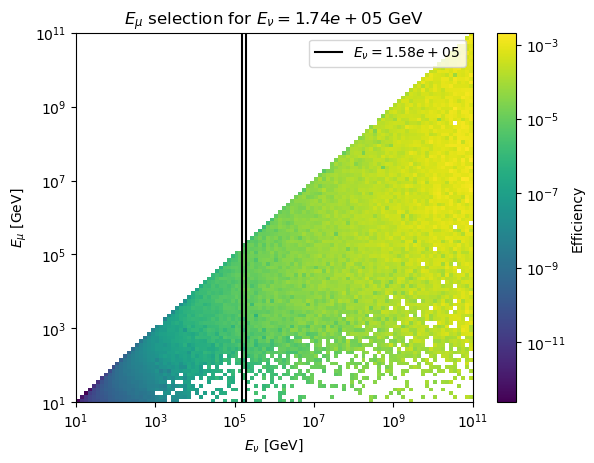

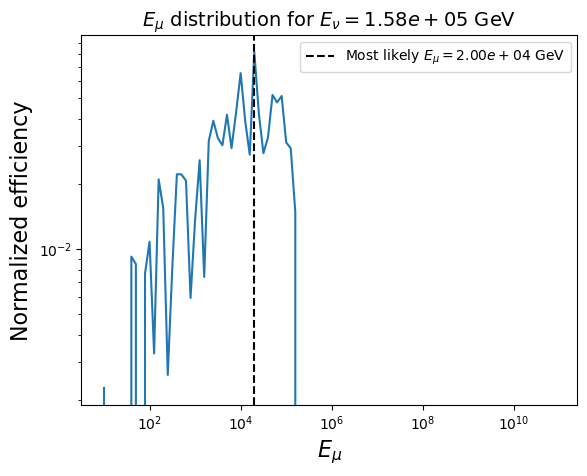

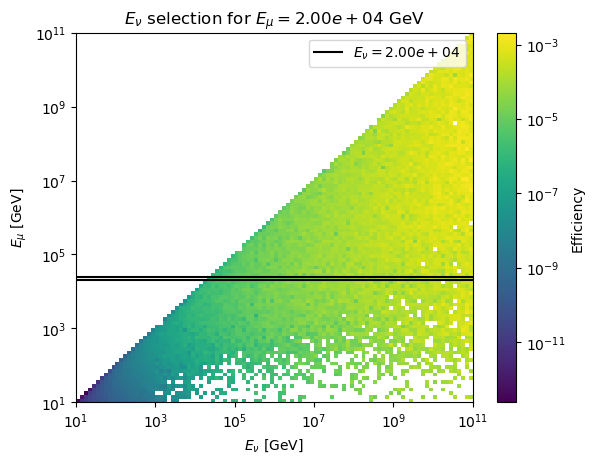

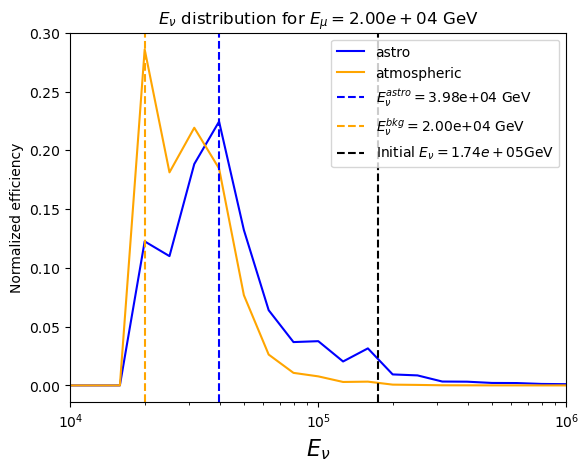

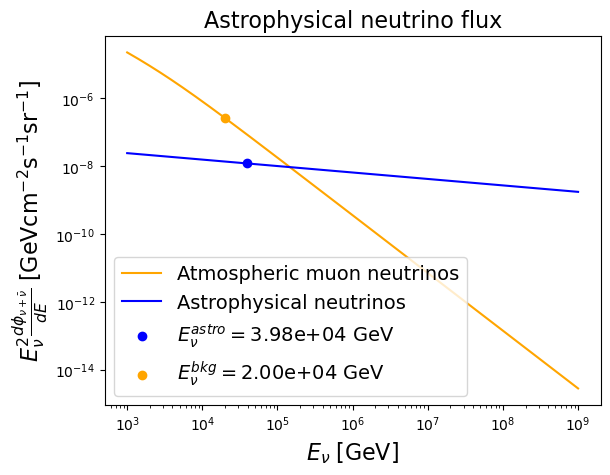

E_nu IceCat-1:  174.0  TeV
Decclination:  3.88
IceCat-1 Signalness:  0.438
Integrated signalness:  0.9094520639404555
Differential signalness:  0.6898443969006922


In [78]:
#single example:
source = ic_alerts.iloc[30]

signalness_diff = get_signalness_diff(source['ENERGY'] * 1e3, source['DEC'])
signalness_int = get_signalness_int(source['ENERGY'] * 1e3, source['DEC'], channel=source['I3TYPE'])


E_nu_astro, E_nu_bkg = get_E_nu(source['ENERGY']  *1e3, 90, plot_stages=True)

E_range = np.logspace(3, 9, 1000)
plt.plot(E_range, flux.getFlux(nu_type, E_range, nu_cos_zenith) * E_range **  2, label='Atmospheric muon neutrinos', c='orange')
plt.plot(E_range, d_N_astro_dE(E_range) *  E_range **  2, label='Astrophysical neutrinos', c='blue')

# Integration points we just found
plt.scatter(E_nu_astro, d_N_astro_dE(E_nu_astro) *  E_nu_astro **  2, c='blue', label=r'$E_\nu^{astro}=$'+f'{E_nu_astro:.2e} GeV')
plt.scatter(E_nu_bkg, flux.getFlux(nu_type, E_nu_bkg, nu_cos_zenith) * E_nu_bkg **  2, c='orange', label=r'$E_\nu^{bkg}=$'+f'{E_nu_bkg:.2e} GeV')


plt.xscale('log')
plt.yscale('log')
plt.xlabel(r'$E_\nu\;[\text{GeV}]$', fontsize=16)
plt.ylabel(r'$E_\nu^2\frac{d\phi_{\nu+\bar \nu}}{dE} \;[\text{GeV}\text{cm}^{-2}\text{s}^{-1}\text{sr}^{-1}]$', fontsize=16)
plt.title("Astrophysical neutrino flux", fontsize=16)
plt.legend(fontsize=14)
plt.show()

print("E_nu IceCat-1: ", source['ENERGY'], ' TeV')
print("Decclination: ", source['DEC'])
print("IceCat-1 Signalness: ", source['SIGNAL'])
print("Integrated signalness: ", signalness_int)
print("Differential signalness: ", signalness_diff)

In [ ]:
#Distribution study



In [37]:

n = 0
diff_signalness = []
int_signalness = []
for alert in ic_alerts.iloc:
    #EHE  GOLD IS A PROBLEM
   

    signalness_diff = get_signalness_diff(alert['ENERGY'] * 1e3, alert['DEC'])
    if alert['I3TYPE'] == 'ehe-gold':
        signalness_int = get_signalness_int(alert['ENERGY'] * 1e3, alert['DEC'], channel='all-gold-only')
    else:
        signalness_int = get_signalness_int(alert['ENERGY'] * 1e3, alert['DEC'], channel=alert['I3TYPE'])

    diff_signalness.append(signalness_diff)
    int_signalness.append(signalness_int)
    print('n ', n, ' ; SIGNAL: ', alert['SIGNAL'], '  diff SIGNAL: ', signalness_diff,  '  int SIGNAL', signalness_int)
    # n+=1

n  0  ; SIGNAL:  0.508   diff SIGNAL:  0.6902297909314824   int SIGNAL 0.9340083306147284
n  0  ; SIGNAL:  0.75   diff SIGNAL:  0.7824118956735953   int SIGNAL 0.9023714768388765
n  0  ; SIGNAL:  0.257   diff SIGNAL:  0.5259862837177164   int SIGNAL 0.833312937107913
n  0  ; SIGNAL:  0.778   diff SIGNAL:  0.29648504116662777   int SIGNAL 0.618421619253047
n  0  ; SIGNAL:  0.396   diff SIGNAL:  0.6886865173661759   int SIGNAL 0.8954012634909381


KeyboardInterrupt: 

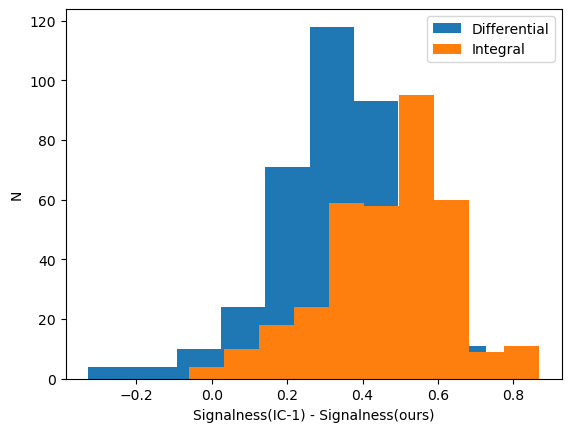

In [158]:
#THINGS TO COMPARE
# difference as a function of declination
#average  difference per channel
# icecat_signalness = []
# for alert in ic_alerts.iloc:
#     icecat_signalness.append(alert['SIGNAL'])

signalness_difference_diff = np.array(diff_signalness) -  ic_alerts['SIGNAL'].values  
signalness_difference_int = np.array(int_signalness) -  ic_alerts['SIGNAL'].values  


plt.hist(signalness_difference_diff, label='Differential')
plt.hist(signalness_difference_int, label='Integral')
plt.xlabel('Signalness(IC-1) - Signalness(ours)')
plt.ylabel('N')
plt.legend()
plt.show()


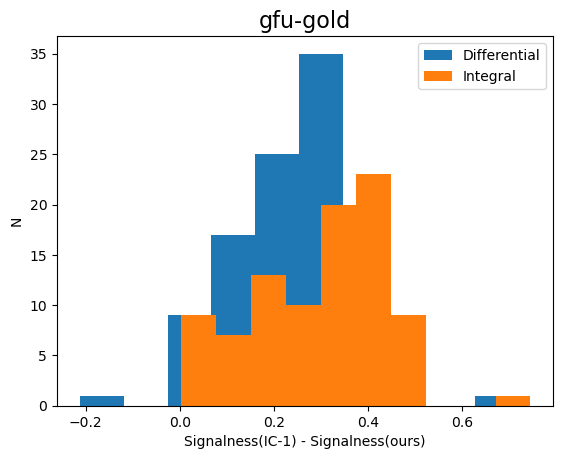

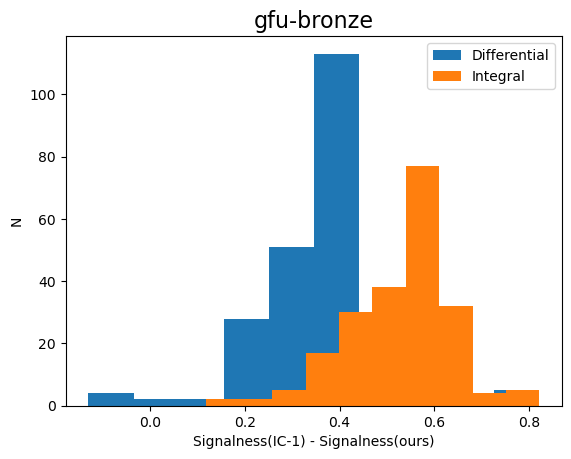

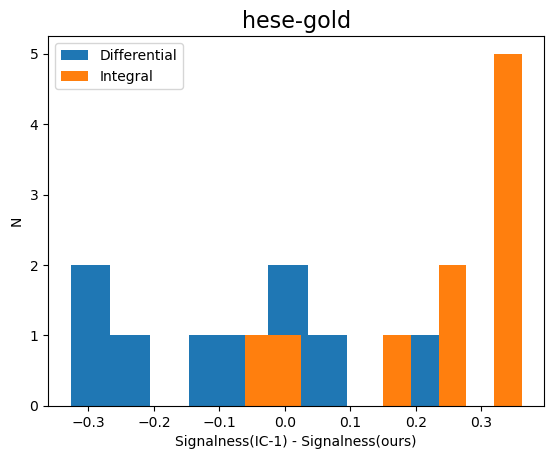

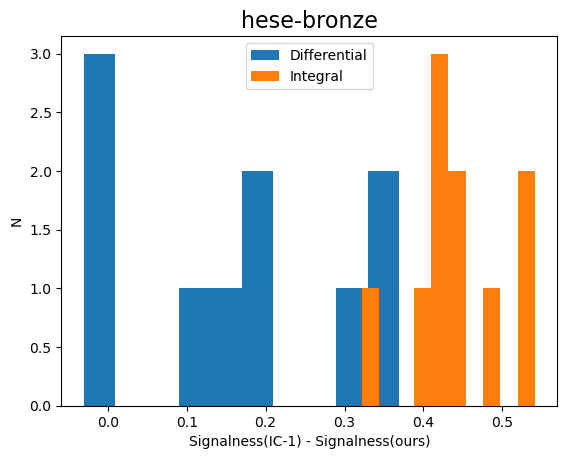

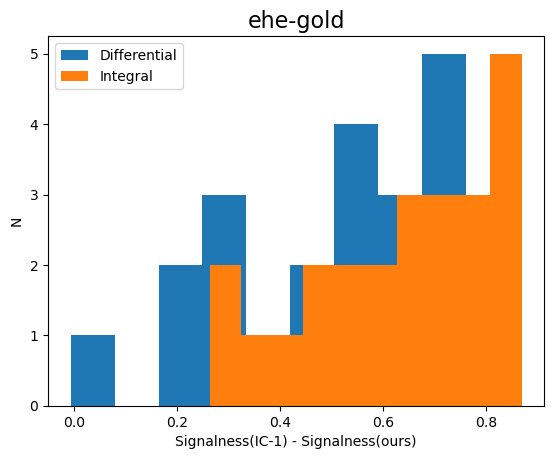

In [161]:
#Per type
for key in ['gfu-gold', 'gfu-bronze', 'hese-gold', 'hese-bronze', 'ehe-gold']:
    plt.hist(signalness_difference_diff[ic_alerts['I3TYPE'] == key], label='Differential')
    plt.hist(signalness_difference_int[ic_alerts['I3TYPE'] == key], label='Integral')
    plt.title(key, fontsize=16)
    plt.xlabel('Signalness(IC-1) - Signalness(ours)')    
    plt.ylabel('N')
    plt.legend()
    plt.show()
    


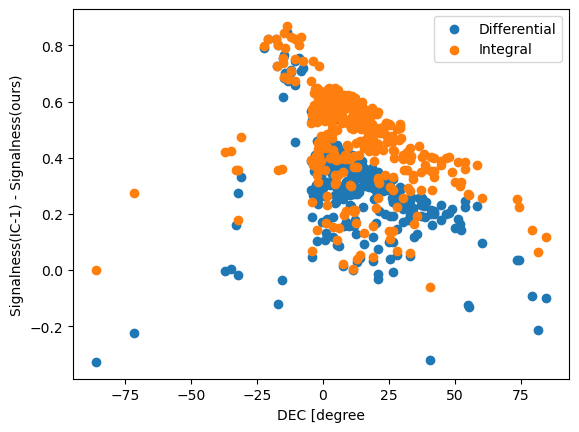

In [163]:
#dec dependancy
plt.scatter(ic_alerts['DEC'], signalness_difference_diff, label='Differential') 
plt.scatter(ic_alerts['DEC'], signalness_difference_int, label='Integral') 
plt.xlabel('DEC [degree')
plt.ylabel('Signalness(IC-1) - Signalness(ours)') 
plt.legend()
plt.show()

In [15]:
a = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
b = a.mean(axis=0)
a

array([[1, 2, 3],
       [4, 5, 6],
       [7, 8, 9]])

In [16]:
b

array([4., 5., 6.])